# 01 Exploratory data analysis

IPL ball-by-ball data from Cricsheet, seasons 2008 to 2025, parsed with
`cricket_ba.parse`. The aim here is to understand the data well enough to choose a
modelling target, a train/test split and the features, and to find data quality issues
before they reach a model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cricket_ba.parse import innings_totals, load_match, parse_dir

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
JSON_DIR = ROOT / "cricket_data" / "ipl_json"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 120)

matches, d = parse_dir(JSON_DIR, seasons=range(2008, 2026))
print(f"{len(matches)} matches, {len(d):,} deliveries, seasons {d.season.min()} to {d.season.max()}")

1169 matches, 278,205 deliveries, seasons 2008 to 2025


## Data checks

The JSON has no scorecard totals, but the second innings carries a `target`, which is
the first-innings total plus one unless Duckworth-Lewis (D/L) changed it. That gives an
independent check of the parsed runs for every match.

In [2]:
tot = innings_totals(d).set_index(["match_id", "innings"])
checked, mismatched = 0, []
for mid in matches.match_id:
    data = load_match(JSON_DIR / f"{mid}.json")
    if data["info"]["outcome"].get("method"):
        continue
    for inn in data["innings"]:
        if "target" in inn and not inn.get("super_over"):
            checked += 1
            if tot.loc[(mid, 1), "runs"] != inn["target"]["runs"] - 1:
                mismatched.append(mid)
print(f"first-innings total = target - 1 in {checked - len(mismatched)} of {checked} non-D/L chases")

first-innings total = target - 1 in 1142 of 1142 non-D/L chases


In [3]:
print("results:", matches.result.value_counts().to_dict())
print("D/L matches:", matches.method.notna().sum())
print("super-over innings:", d.groupby(["match_id", "innings"]).is_super_over.first().sum())
print("wicket kinds:", d.wicket_kind.value_counts().to_dict())

results: {'win': 1146, 'tie': 15, 'no result': 8}
D/L matches: 22
super-over innings: 32
wicket kinds: {'caught': 8665, 'bowled': 2345, 'run out': 1153, 'lbw': 853, 'caught and bowled': 388, 'stumped': 376, 'hit wicket': 18, 'retired hurt': 17, 'retired out': 5, 'obstructing the field': 3}


### Player names and ids

Cricsheet gives short names ("RG Sharma") and a registry id for each person. Names are
not unique keys, so the models use the ids.

In [4]:
names = pd.concat(
    [
        d[["batter", "batter_id"]].set_axis(["name", "id"], axis=1),
        d[["bowler", "bowler_id"]].set_axis(["name", "id"], axis=1),
    ]
).drop_duplicates()
per_name = names.groupby("name").id.nunique()
per_id = names.groupby("id").name.nunique()
print("names shared by more than one person:", per_name[per_name > 1].to_dict())
print("people recorded under more than one name:")
print(names[names.id.isin(per_id[per_id > 1].index)].sort_values("id").to_string(index=False))

names shared by more than one person: {'Harmeet Singh': 2}
people recorded under more than one name:
           name       id
    Arshad Khan 12314277
Arshad Khan (2) 12314277
  Navdeep Saini 21d4e29b
       NA Saini 21d4e29b


### Venue names

The same ground appears under several names: with and without the city, with different
punctuation, and after renaming. 59 raw names reduce to fewer grounds after taking the
text before the first comma, tidying punctuation and mapping three renames. Motera
(Sardar Patel Stadium) and the Narendra Modi Stadium are kept apart because the ground
was rebuilt between them.

In [5]:
RENAMES = {
    "Feroz Shah Kotla": "Arun Jaitley Stadium",
    "Sheikh Zayed Stadium": "Zayed Cricket Stadium",
    "Punjab Cricket Association Stadium": "Punjab Cricket Association IS Bindra Stadium",
}


def clean_venue(v: pd.Series) -> pd.Series:
    out = v.str.split(",").str[0].str.replace(".", " ", regex=False)
    out = out.str.replace(r"\s+", " ", regex=True).str.strip()
    return out.replace(RENAMES)


matches["venue_clean"] = clean_venue(matches.venue)
print(matches.venue.nunique(), "raw venue names ->", matches.venue_clean.nunique(), "grounds")
(
    matches.groupby("venue_clean")
    .agg(names=("venue", "unique"), matches=("match_id", "size"))
    .pipe(lambda t: t[t["names"].str.len() > 1])
)

59 raw venue names -> 38 grounds


,names,matches
venue_clean,,
Arun Jaitley Stadium,"[Feroz Shah Kotla, Arun Jaitley Stadium, Arun ...",97
Brabourne Stadium,"[Brabourne Stadium, Brabourne Stadium, Mumbai]",27
Dr DY Patil Sports Academy,"[Dr DY Patil Sports Academy, Dr DY Patil Sport...",37
Dr Y S Rajasekhara Reddy ACA-VDCA Cricket Stadium,[Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket S...,17
Eden Gardens,"[Eden Gardens, Eden Gardens, Kolkata]",100
Himachal Pradesh Cricket Association Stadium,"[Himachal Pradesh Cricket Association Stadium,...",15
M Chinnaswamy Stadium,"[M Chinnaswamy Stadium, M.Chinnaswamy Stadium,...",99
MA Chidambaram Stadium,"[MA Chidambaram Stadium, Chepauk, MA Chidambar...",91
Maharaja Yadavindra Singh International Cricket Stadium,[Maharaja Yadavindra Singh International Crick...,11


## Target

The question for the models is: **on a legal ball, does the bowler take the striker's
wicket?** That is bowled, caught, caught and bowled, lbw, stumped or hit wicket. It is
the cleanest outcome to attribute to a batter and a bowler. Run outs (shared by both
batters and fielders) and retirements are not counted, and super overs are dropped.
A stumping off a wide is a bowler's wicket but not on a legal ball, so it falls outside
the target; there are only a few.

In [6]:
print("bowler wickets off wides or no-balls:", (d.bowler_wicket & ~d.legal_ball).sum())

legal = d[d.legal_ball & ~d.is_super_over].copy()
legal["phase"] = pd.cut(
    legal.over, [-1, 5, 14, 19], labels=["powerplay", "middle", "death"]
).astype(str)
legal = legal.merge(matches[["match_id", "venue_clean"]], on="match_id", how="left")
legal["wicket"] = legal.bowler_wicket.astype(int)
print(f"{len(legal):,} legal balls, {legal.wicket.sum():,} bowler wickets, rate {legal.wicket.mean():.4f}")

bowler wickets off wides or no-balls: 39


267,801 legal balls, 12,586 bowler wickets, rate 0.0470


## The long tail of players

Most players have little data. This is the case for partial pooling: a batter dismissed
once in 20 balls should not be given a 5% dismissal rate with confidence.

In [7]:
balls_batter = legal.groupby("batter_id").size()
balls_bowler = legal.groupby("bowler_id").size()
summary = pd.DataFrame(
    {
        "players": [len(balls_batter), len(balls_bowler)],
        "median balls": [balls_batter.median(), balls_bowler.median()],
        "share under 100 balls": [(balls_batter < 100).mean(), (balls_bowler < 100).mean()],
        "share under 300 balls": [(balls_batter < 300).mean(), (balls_bowler < 300).mean()],
    },
    index=["batters", "bowlers"],
)
summary.round(3)

,players,median balls,share under 100 balls,share under 300 balls
batters,702,72.5,0.567,0.751
bowlers,549,188.0,0.370,0.638


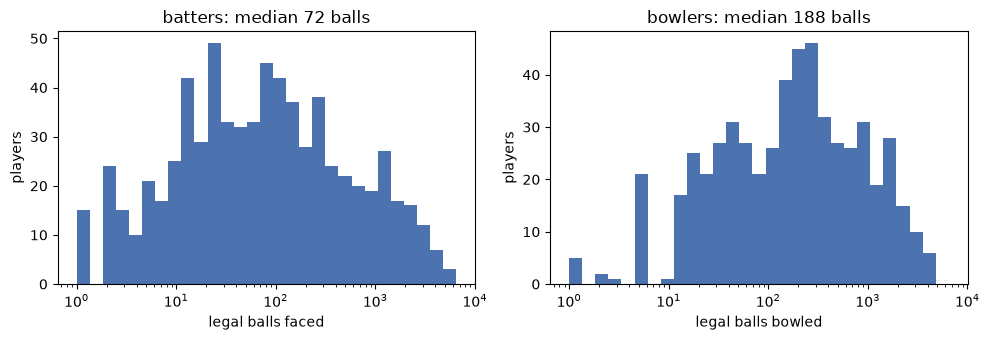

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
bins = np.logspace(0, np.log10(max(balls_batter.max(), balls_bowler.max())), 30)
for a, s, label in [(ax[0], balls_batter, "batters"), (ax[1], balls_bowler, "bowlers")]:
    a.hist(s, bins=bins, color="#4c72b0")
    a.set_xscale("log")
    a.set_xlabel("legal balls faced" if label == "batters" else "legal balls bowled")
    a.set_ylabel("players")
    a.set_title(f"{label}: median {s.median():.0f} balls")
fig.tight_layout()
fig.savefig(FIG / "balls_per_player.png", dpi=120)

A raw dismissal rate is noisy for thin players. The spread of raw rates is far wider
for players with few balls, much of it binomial noise rather than skill.

In [9]:
bat = legal.groupby("batter_id").agg(balls=("wicket", "size"), wickets=("wicket", "sum"))
bat["rate"] = bat.wickets / bat.balls
bat["band"] = pd.cut(bat.balls, [0, 30, 100, 300, 1000, np.inf])
bat.groupby("band", observed=True).rate.describe()[["count", "mean", "std", "min", "max"]].round(3)

,count,mean,std,min,max
band,,,,,
"(0.0, 30.0]",259.0,0.134,0.171,0.000,1.000
"(30.0, 100.0]",141.0,0.080,0.039,0.012,0.205
"(100.0, 300.0]",128.0,0.063,0.019,0.019,0.119
"(300.0, 1000.0]",90.0,0.053,0.014,0.026,0.106
"(1000.0, inf]",84.0,0.043,0.010,0.027,0.087


## Rates by season, phase and venue

,wicket_rate,runs_per_ball,balls
season,,,
2008,0.0466,1.3236,12950
2009,0.0473,1.1944,13085
2010,0.0447,1.2981,13929
2011,0.0448,1.2380,16425
2012,0.0448,1.2602,17208
2013,0.0470,1.2384,17613
2014,0.0437,1.3222,13833
2015,0.0474,1.3462,13141
2016,0.0432,1.3371,13618


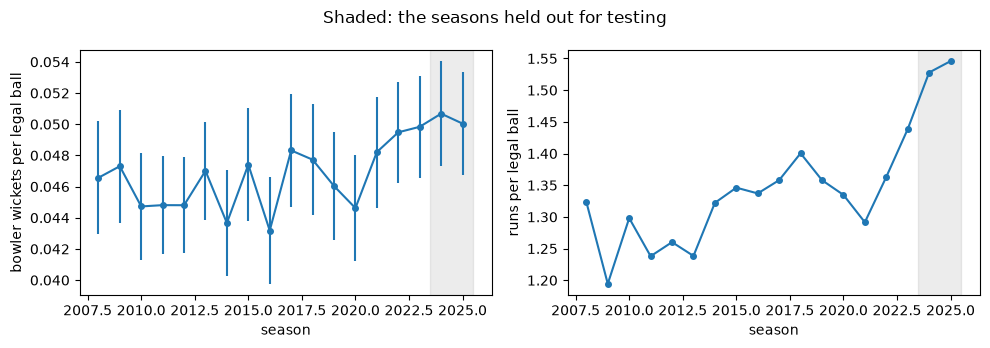

In [10]:
by_season = legal.groupby("season").agg(
    wicket_rate=("wicket", "mean"), runs_per_ball=("runs_total", "mean"), balls=("wicket", "size")
)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
se = np.sqrt(by_season.wicket_rate * (1 - by_season.wicket_rate) / by_season.balls)
ax[0].errorbar(by_season.index, by_season.wicket_rate, yerr=1.96 * se, fmt="o-", ms=4)
ax[0].set_ylabel("bowler wickets per legal ball")
ax[1].plot(by_season.index, by_season.runs_per_ball, "o-", ms=4)
ax[1].set_ylabel("runs per legal ball")
for a in ax:
    a.axvspan(2023.5, 2025.5, color="grey", alpha=0.15)
    a.set_xlabel("season")
fig.suptitle("Shaded: the seasons held out for testing")
fig.tight_layout()
fig.savefig(FIG / "rates_by_season.png", dpi=120)
by_season.round(4)

Both runs and wickets per ball have risen since 2022, and the 2024 and 2025 wicket rates
are above every earlier season. Any model trained on earlier seasons will start the test
seasons slightly low. I keep that in mind when reading calibration later.

In [11]:
legal.groupby("phase").agg(
    wicket_rate=("wicket", "mean"), runs_per_ball=("runs_total", "mean"), balls=("wicket", "size")
).loc[["powerplay", "middle", "death"]].round(4)

,wicket_rate,runs_per_ball,balls
phase,,,
powerplay,0.0375,1.2735,83875
middle,0.0402,1.2708,123771
death,0.0741,1.5978,60155


In [12]:
by_venue = legal.groupby("venue_clean").agg(
    wicket_rate=("wicket", "mean"), balls=("wicket", "size"), matches=("match_id", "nunique")
)
by_venue["se"] = np.sqrt(by_venue.wicket_rate * (1 - by_venue.wicket_rate) / by_venue.balls)
by_venue.sort_values("balls", ascending=False).head(15).round(4)

,wicket_rate,balls,matches,se
venue_clean,,,,
Wankhede Stadium,0.0485,28872,125,0.0013
Eden Gardens,0.0459,22615,100,0.0014
Arun Jaitley Stadium,0.0462,22132,97,0.0014
M Chinnaswamy Stadium,0.0477,22021,99,0.0014
MA Chidambaram Stadium,0.0474,21285,91,0.0015
Rajiv Gandhi International Stadium,0.0459,18964,83,0.0015
Sawai Mansingh Stadium,0.0425,14646,64,0.0017
Punjab Cricket Association IS Bindra Stadium,0.0450,14030,61,0.0017
Dubai International Cricket Stadium,0.0464,10777,46,0.0020


Venue rates differ by a few tenths of a percentage point, with standard errors of a
similar size for most grounds. Whether venue is worth a feature is a question for
cross-validation in the baseline notebook, not for this table.

## Choices carried forward

* Target: bowler-credited wicket on a legal ball, super overs excluded.
* Split by time: train on 2008 to 2023, test on 2024 and 2025.
* Players keyed by Cricsheet registry id. Venues cleaned as above.

In [13]:
test = legal.season >= 2024
seen_bat = set(legal.loc[~test, "batter_id"])
seen_bowl = set(legal.loc[~test, "bowler_id"])
print(f"train {(~test).sum():,} balls, test {test.sum():,} balls")
print(f"test balls with a batter unseen in training: {(~legal.loc[test, 'batter_id'].isin(seen_bat)).mean():.3f}")
print(f"test balls with a bowler unseen in training: {(~legal.loc[test, 'bowler_id'].isin(seen_bowl)).mean():.3f}")

cols = [
    "match_id", "date", "season", "innings", "over", "phase", "venue_clean",
    "batter", "batter_id", "bowler", "bowler_id", "runs_total", "wicket",
]
out = ROOT / "data" / "legal_balls.parquet"
out.parent.mkdir(exist_ok=True)
legal[cols].to_parquet(out, index=False)
print("wrote", out.relative_to(ROOT))

train 234,995 balls, test 32,806 balls
test balls with a batter unseen in training: 0.127
test balls with a bowler unseen in training: 0.112
wrote data/legal_balls.parquet
